In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import randint
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector, make_column_transformer
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split, HalvingRandomSearchCV
from sklearn.metrics import make_scorer, f1_score

In [2]:
from sklearn import set_config
set_config(display="diagram")

In [3]:
#Load the dataset
alzh_data = pd.read_csv('alzheimers_prediction_dataset.csv')
alzh_data.head()

,Country,Age,Gender,Education Level,BMI,Physical Activity Level,Smoking Status,Alcohol Consumption,Diabetes,Hypertension,...,Dietary Habits,Air Pollution Exposure,Employment Status,Marital Status,Genetic Risk Factor (APOE-ε4 allele),Social Engagement Level,Income Level,Stress Levels,Urban vs Rural Living,Alzheimer’s Diagnosis
0,Spain,90,Male,1,33.0,Medium,Never,Occasionally,No,No,...,Healthy,High,Retired,Single,No,Low,Medium,High,Urban,No
1,Argentina,72,Male,7,29.9,Medium,Former,Never,No,No,...,Healthy,Medium,Unemployed,Widowed,No,High,Low,High,Urban,No
2,South Africa,86,Female,19,22.9,High,Current,Occasionally,No,Yes,...,Average,Medium,Employed,Single,No,Low,Medium,High,Rural,No
3,China,53,Male,17,31.2,Low,Never,Regularly,Yes,No,...,Healthy,Medium,Retired,Single,No,High,Medium,Low,Rural,No
4,Sweden,58,Female,3,30.0,High,Former,Never,Yes,No,...,Unhealthy,High,Employed,Married,No,Low,Medium,High,Rural,No


In [4]:
len(alzh_data)

74283

In [5]:
alzh_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 74283 entries, 0 to 74282
Data columns (total 25 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Country                               74283 non-null  str    
 1   Age                                   74283 non-null  int64  
 2   Gender                                74283 non-null  str    
 3   Education Level                       74283 non-null  int64  
 4   BMI                                   74283 non-null  float64
 5   Physical Activity Level               74283 non-null  str    
 6   Smoking Status                        74283 non-null  str    
 7   Alcohol Consumption                   74283 non-null  str    
 8   Diabetes                              74283 non-null  str    
 9   Hypertension                          74283 non-null  str    
 10  Cholesterol Level                     74283 non-null  str    
 11  Family History of Alzheime

In [6]:
# Search for all unique values in string columns, but the Country.
# In order to change the dtype of these files to categories, if possible
# to reduce memory usage and speed up the process:
uniq_vals = {}
for col in alzh_data.select_dtypes(include=str).columns:
    uniq_vals[col] = alzh_data[col].nunique()
number_of_uniq_vals = pd.Series(uniq_vals)
number_of_uniq_vals

Country                                 20
Gender                                   2
Physical Activity Level                  3
Smoking Status                           3
Alcohol Consumption                      3
Diabetes                                 2
Hypertension                             2
Cholesterol Level                        2
Family History of Alzheimer’s            2
Depression Level                         3
Sleep Quality                            3
Dietary Habits                           3
Air Pollution Exposure                   3
Employment Status                        3
Marital Status                           3
Genetic Risk Factor (APOE-ε4 allele)     2
Social Engagement Level                  3
Income Level                             3
Stress Levels                            3
Urban vs Rural Living                    2
Alzheimer’s Diagnosis                    2
dtype: int64

In [7]:
# Changing the dtypes
alzh_data[number_of_uniq_vals.index] = alzh_data[number_of_uniq_vals.index].astype("category")
alzh_data[alzh_data.select_dtypes(include=np.int64).columns] = alzh_data[alzh_data.select_dtypes(include=np.int64).columns].astype(np.int32)
alzh_data["BMI"] = alzh_data["BMI"].astype(np.float32).round(2)

In [8]:
# Great! we reduced the memory usage by almost 12 MB (82% Reduction)
alzh_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 74283 entries, 0 to 74282
Data columns (total 25 columns):
 #   Column                                Non-Null Count  Dtype   
---  ------                                --------------  -----   
 0   Country                               74283 non-null  category
 1   Age                                   74283 non-null  int32   
 2   Gender                                74283 non-null  category
 3   Education Level                       74283 non-null  int32   
 4   BMI                                   74283 non-null  float32 
 5   Physical Activity Level               74283 non-null  category
 6   Smoking Status                        74283 non-null  category
 7   Alcohol Consumption                   74283 non-null  category
 8   Diabetes                              74283 non-null  category
 9   Hypertension                          74283 non-null  category
 10  Cholesterol Level                     74283 non-null  category
 11  Family Histor

In [9]:
# Let's take a glance at the data:
alzh_data.describe()

,Age,Education Level,BMI,Cognitive Test Score
count,74283.000000,74283.000000,74283.000000,74283.000000
mean,71.964703,9.487514,26.780640,64.654241
std,12.980748,5.757020,4.764679,20.153247
min,50.000000,0.000000,18.500000,30.000000
25%,61.000000,4.000000,22.700001,47.000000
50%,72.000000,9.000000,26.799999,65.000000
75%,83.000000,14.000000,30.900000,82.000000
max,94.000000,19.000000,35.000000,99.000000


In [10]:
# Let's check for any null values:
alzh_data.isnull().any()

Country                                 False
Age                                     False
Gender                                  False
Education Level                         False
BMI                                     False
Physical Activity Level                 False
Smoking Status                          False
Alcohol Consumption                     False
Diabetes                                False
Hypertension                            False
Cholesterol Level                       False
Family History of Alzheimer’s           False
Cognitive Test Score                    False
Depression Level                        False
Sleep Quality                           False
Dietary Habits                          False
Air Pollution Exposure                  False
Employment Status                       False
Marital Status                          False
Genetic Risk Factor (APOE-ε4 allele)    False
Social Engagement Level                 False
Income Level                      

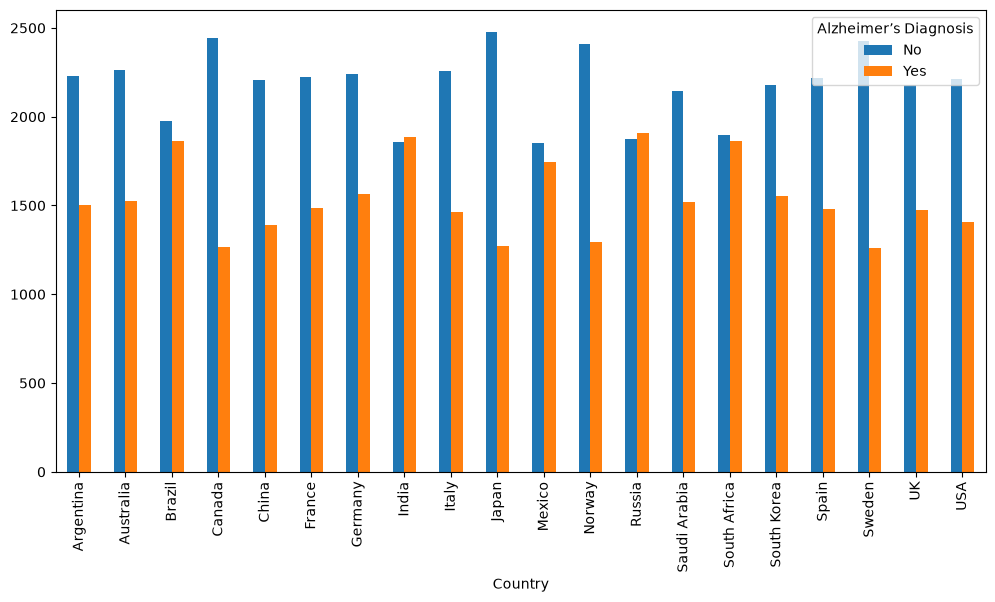

In [11]:
# It's time to check if there is any correlation between Country and our labels.
counts = (
    alzh_data
    .groupby(["Country", "Alzheimer’s Diagnosis"])
    .size()
    .unstack(fill_value=0)
)

counts.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.show()

In [12]:
# Let's check the labels, with respect of data snooping bias:
alzh_data["Alzheimer’s Diagnosis"].value_counts()

Alzheimer’s Diagnosis
No     43570
Yes    30713
Name: count, dtype: int64

In [13]:
# Country should be dropped, because it has not significant correlation with our labels.
alzh_data.drop("Country", axis=1, inplace=True)

In [14]:
# Here we used Stratified Sampling, based on Gender feature.
# Different gender may have different chance of getting Alzheimer.

fem_ratio = round(len(alzh_data[alzh_data["Gender"] == "Female"]) / len(alzh_data) * 100, 2)
male_ratio = round(len(alzh_data[alzh_data["Gender"] == "Male"]) / len(alzh_data) * 100, 2)
print(f"Percentage of inspections per Gender: \n  Male: {male_ratio}%  |  Female: {fem_ratio}%")

strat_train_set, strat_test_set = train_test_split(
    alzh_data, test_size=0.2, stratify=alzh_data["Gender"], random_state=42
)

Percentage of inspections per Gender: 
  Male: 49.86%  |  Female: 50.14%


In [15]:
# It is time to prepare our labels

train_set_features = strat_train_set.drop("Alzheimer’s Diagnosis", axis=1) # It creates a copy itself.
train_set_labels = strat_train_set["Alzheimer’s Diagnosis"].copy()

label_encoder = LabelEncoder()
alzh_labels = label_encoder.fit_transform(train_set_labels)

In [16]:
# Here, I wrote the column names to use different encoder, based on their type.
bool_cols = ["Diabetes", "Hypertension", "Cholesterol Level",
             "Family History of Alzheimer’s",
             "Genetic Risk Factor (APOE-ε4 allele)", "Urban vs Rural Living"]

ord_cols = ["Physical Activity Level", "Depression Level", "Sleep Quality",
            "Dietary Habits", "Air Pollution Exposure",
            "Social Engagement Level", "Income Level",
            "Stress Levels"] # Ordinal Columns

cat_cols = ["Gender", "Smoking Status", "Alcohol Consumption",
            "Employment Status", "Marital Status"]

In [17]:
# Let's write pipelines (Just the preprocessing steps):
# This csv file does not have nan values, but I used SimpleImputer just in case
# of facing nan values in the future:
bool_ord_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"), OrdinalEncoder()
)
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", drop="first")
)
num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler()
)

In [18]:
# Wrap them up in ColumnTransformer:
preprocessing = ColumnTransformer([
    ("Boolean (Binary) Pipeline", bool_ord_pipeline, bool_cols),
    ("Ordinal Pipeline", bool_ord_pipeline, ord_cols),
    ("Categorical Pipeline", cat_pipeline, cat_cols),
    ("Numerical Pipeline", num_pipeline, make_column_selector(dtype_include=np.number))
])

In [19]:
alzh_prepared = preprocessing.fit_transform(train_set_features)
alzh_prepared.shape

(59426, 27)

In [20]:
full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestClassifier(random_state=42))
])
full_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Boolean (Binary) Pipeline', ...), ('Ordinal Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thr

In [21]:
# Let's fit our model:
full_pipeline.fit(train_set_features, train_set_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Age','Gender','Education Level',...,'Income Level','Stress Levels', 'Urban vs Rural Living']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Boolean (Binary) Pipeline', ...), ('Ordinal Pipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are 

In [22]:
alzh_pred = full_pipeline.predict(strat_test_set.drop("Alzheimer’s Diagnosis", axis=1))
f1_score(strat_test_set["Alzheimer’s Diagnosis"], alzh_pred,
         labels=["Yes", "No"], pos_label="Yes")

0.6531122406466128

In [ ]:
# Optional - use the sklearn f1-score package instead... XD
# Handwritten F1 Score Function (F1 score= Harmonic mean of precision and recall):

def h_f1_score(y_true, y_pred): # Handwritten f1 score function
    TP = np.sum(y_true & y_pred)
    TN = np.sum(~y_true & ~y_pred)
    FP = np.sum(~y_true & y_pred)
    FN = np.sum(y_true & ~y_pred)

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    
    f1_score = 2 * ((precision * recall) / (precision + recall))
    return f1_score

In [ ]:
# Let's fine-tune our model:
# We are performing tests on validation set, before take the algorithm to the actual test,
# in order to find the best hyperparameters possible:
param_dist = {'random_forest__max_features': randint(low=5, high=25)}

# Better version
# (Run the code below if you have better memory, as well as infinite amount of time):
# param_dist = {
#     'random_forest__n_estimators': randint(100, 500),
#     'random_forest__max_features': randint(2, 60),
#     'random_forest__max_depth': [None, 10, 20, 30, 40],
#     'random_forest__min_samples_split': randint(2, 20),
#     'random_forest__min_samples_leaf': randint(1, 10)
# }

f1_yes = make_scorer(f1_score, labels=["Yes", "No"], pos_label ="Yes")

rnd_search = HalvingRandomSearchCV(full_pipeline, param_dist,
                                   cv=3, scoring=f1_yes, random_state=42)
rnd_search.fit(train_set_features, train_set_labels)
rnd_search.best_params_ # prints out the best parameter values

In [23]:
# Save the model:
joblib.dump(full_pipeline, "Alzheimer’s_Diagnosis_RFC.pkl")

['Alzheimer’s_Diagnosis_RFC.pkl']

In [24]:
# Reload the model again:
model_reload = joblib.load("Alzheimer’s_Diagnosis_RFC.pkl")

In [25]:
# Predict some real values:
model_reload.predict(strat_test_set.drop("Alzheimer’s Diagnosis", axis=1))

array(['No', 'No', 'No', ..., 'No', 'Yes', 'Yes'],
      shape=(14857,), dtype=object)